# Técnicas avançadas: o que os dados escondem e onde está o sinal

Este é o terceiro notebook de uma sequência. O primeiro (`demo_criacao_target.ipynb`) construiu a variável TARGET a partir do histórico de pagamento e defendeu que o critério de inadimplência é uma decisão de negócio, não estatística. O segundo (`demo_modelagem_desbalanceada.ipynb`) aplicou o pipeline completo de modelagem sobre esse TARGET desbalanceado — e terminou com uma conclusão desconfortável: avaliado de forma honesta, o cadastro de um solicitante de cartão de crédito quase não carrega informação sobre quem vai atrasar 60 dias ou mais. Nenhuma técnica de balanceamento, busca de hiperparâmetros ou calibração de limiar mudou isso, porque nenhuma delas cria sinal.

Este notebook faz duas coisas. Primeiro, organiza e aprofunda os **problemas** que apareceram pelo caminho e que valem por si só como lições de ciência de dados aplicada: perfis duplicados que vazam entre treino e teste, atributos com poder preditivo praticamente nulo, o viés de exposição embutido em um TARGET do tipo "algum dia atrasou", e o otimismo da validação cruzada quando os positivos são poucos. Segundo, mostra **onde o sinal de fato está** — no comportamento de pagamento ao longo do tempo — reformulando o problema como um *behavioral scoring* com janelas de observação e performance bem definidas, e discute como ler o resultado da forma que uma área de crédito leria: em termos de captura de risco nos clientes mais arriscados, não de um F1 no limiar 0,5. Fechamos com uma rodada final sobre os dados deduplicados, no nível da pessoa, para deixar registrado o que sobra do cadastro quando a repetição de perfis é removida.

O tom continua o mesmo dos notebooks anteriores: cada número reportado aqui foi obtido com pessoas que o modelo nunca viu, e quando um resultado é fraco, ele é apresentado como fraco.

## Onde colocar os dados

Mesma convenção dos notebooks anteriores: execução a partir de `notebooks/`, dados brutos em `../data/raw/` (`application_record.csv` e `credit_record.csv`, do dataset [rikdifos/credit-card-approval-prediction](https://www.kaggle.com/datasets/rikdifos/credit-card-approval-prediction)). Se for executar fora dessa estrutura, ajuste `DATA_DIR` na célula abaixo. Este notebook usa `xgboost` além das dependências dos anteriores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    f1_score, precision_score, recall_score,
)
from xgboost import XGBClassifier

pd.set_option("display.width", 160)
RANDOM_STATE = 42

DATA_DIR = Path("../data/raw")
APPLICATION_PATH = DATA_DIR / "application_record.csv"
CREDIT_PATH = DATA_DIR / "credit_record.csv"
for path in (APPLICATION_PATH, CREDIT_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado em {path.resolve()}. Ajuste DATA_DIR.")

credit_record = pd.read_csv(CREDIT_PATH)
application_record = pd.read_csv(APPLICATION_PATH).drop_duplicates(subset="ID", keep="first")
print("credit_record:", credit_record.shape, "| application_record:", application_record.shape)

credit_record: (1048575, 3) | application_record: (438510, 18)


## Base de partida

Reconstruímos o TARGET rígido (algum mês com `STATUS` em `2`-`5`, isto é, 60 dias ou mais de atraso) e o pré-processamento mínimo do cadastro, exatamente como no notebook anterior, para que os diagnósticos abaixo falem da mesma base. Definimos também duas funções reutilizadas ao longo do notebook: uma que codifica o cadastro em atributos numéricos, e outra que escolhe o limiar de decisão de forma honesta — maximizando o F1 nas previsões *out-of-fold* do treino, nunca no teste.

In [2]:
credit_record["bad_rigido"] = credit_record["STATUS"].isin(["2", "3", "4", "5"]).astype(int)
target_rigido = credit_record.groupby("ID")["bad_rigido"].max().rename("TARGET").reset_index()
base = application_record.merge(target_rigido, on="ID", how="inner")

colunas_cadastro = [c for c in application_record.columns if c != "ID"]
CATEGORICAS = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE"]


def codificar_cadastro(df):
    df = df.copy()
    df["idade_anos"] = -df["DAYS_BIRTH"] / 365.25
    df["flag_sem_emprego_ativo"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
    df["anos_empregado"] = np.where(df["flag_sem_emprego_ativo"] == 1, 0.0, -df["DAYS_EMPLOYED"] / 365.25)
    df["CODE_GENDER"] = (df["CODE_GENDER"] == "M").astype(int)
    df["FLAG_OWN_CAR"] = (df["FLAG_OWN_CAR"] == "Y").astype(int)
    df["FLAG_OWN_REALTY"] = (df["FLAG_OWN_REALTY"] == "Y").astype(int)
    df["OCCUPATION_TYPE"] = df["OCCUPATION_TYPE"].fillna("Nao_informado")
    df = pd.get_dummies(df, columns=CATEGORICAS, drop_first=True)
    return df.drop(columns=["DAYS_BIRTH", "DAYS_EMPLOYED", "FLAG_MOBIL"])


def limiar_f1_out_of_fold(modelo, X_tr, y_tr, cv, groups=None):
    proba_oof = cross_val_predict(modelo, X_tr, y_tr, cv=cv, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, t = precision_recall_curve(y_tr, proba_oof)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    i = np.nanargmax(f1)
    return t[i], average_precision_score(y_tr, proba_oof)


def avaliar_honesto(nome, modelo, X_tr, y_tr, X_te, y_te, cv, groups=None):
    limiar, ap_oof = limiar_f1_out_of_fold(modelo, X_tr, y_tr, cv, groups)
    modelo.fit(X_tr, y_tr)
    proba = modelo.predict_proba(X_te)[:, 1]
    pred = (proba >= limiar).astype(int)
    return {
        "modelo": nome,
        "AP (out-of-fold, treino)": ap_oof,
        "ROC-AUC (teste)": roc_auc_score(y_te, proba),
        "AP (teste)": average_precision_score(y_te, proba),
        "F1 (teste)": f1_score(y_te, pred),
        "precision (teste)": precision_score(y_te, pred, zero_division=0),
        "recall (teste)": recall_score(y_te, pred),
        "limiar": limiar,
    }, proba


base["grupo_perfil"] = pd.util.hash_pandas_object(base[colunas_cadastro].astype(str), index=False).values
X_cad = codificar_cadastro(base.drop(columns=["TARGET", "grupo_perfil"])).drop(columns="ID")
y_cad = base["TARGET"].astype(int)
grupos_cad = base["grupo_perfil"]
print("Base:", X_cad.shape, "| positivos:", int(y_cad.sum()), f"({y_cad.mean():.2%})")

Base: (36457, 47) | positivos: 616 (1.69%)


## Problema 1 — perfis duplicados que vazam entre treino e teste

O notebook anterior encontrou que 91% dos clientes têm ao menos um "gêmeo" de cadastro idêntico (mesma renda, mesma data de nascimento em dias, mesmo tempo de emprego em dias, mesmas categorias), e que 68% dos maus pagadores têm um gêmeo que é bom pagador. Vale insistir nas duas consequências, porque elas se confundem com facilidade.

A primeira é um **teto de separabilidade**: dois clientes com o mesmo vetor de atributos recebem, de qualquer modelo determinístico, a mesma previsão. Se um é mau pagador e o outro não, o modelo erra um dos dois. Não há hiperparâmetro que resolva isso.

A segunda é um **vazamento de avaliação**: com um split aleatório, o gêmeo de quase todo cliente do teste está no treino. Um modelo flexível memoriza o gêmeo e "acerta" o cliente do teste — e a métrica passa a medir a capacidade de lembrar, não de generalizar. A tabela abaixo repete a comparação do notebook anterior para dois modelos diferentes, para deixar claro que o efeito não é uma peculiaridade da Random Forest. Aqui usamos o melhor F1 ao longo de todos os limiares do teste (uma medida otimista, mas igual para as duas colunas) e as duas métricas de ranking, ROC-AUC e average precision.

In [3]:
def melhor_f1_no_teste(y_true, proba):
    p, r, _ = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return np.nanmax(f1)


def metricas_ranking(modelo, idx_tr, idx_te):
    modelo.fit(X_cad.iloc[idx_tr], y_cad.iloc[idx_tr])
    proba = modelo.predict_proba(X_cad.iloc[idx_te])[:, 1]
    y_te = y_cad.iloc[idx_te]
    return {"ROC-AUC": roc_auc_score(y_te, proba), "AP": average_precision_score(y_te, proba),
            "melhor F1 (teste)": melhor_f1_no_teste(y_te, proba)}


indices = np.arange(len(X_cad))
tr_aleatorio, te_aleatorio = train_test_split(indices, test_size=0.2, stratify=y_cad, random_state=RANDOM_STATE)
tr_grupo, te_grupo = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_cad, y_cad, groups=grupos_cad))

modelos_diag = {
    "RandomForest (class_weight)": lambda: RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost (scale_pos_weight)": lambda: XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.2, subsample=0.8, colsample_bytree=0.6,
                                                       eval_metric="aucpr", random_state=RANDOM_STATE, n_jobs=-1),
}
linhas = []
for nome, criar in modelos_diag.items():
    for split, (tr, te) in (("aleatório", (tr_aleatorio, te_aleatorio)), ("por grupo", (tr_grupo, te_grupo))):
        linhas.append({"modelo": nome, "split": split, **metricas_ranking(criar(), tr, te)})
pd.DataFrame(linhas).set_index(["modelo", "split"]).round(3)

ROC-AUC     AP  melhor F1 (teste)
modelo                      split                                       
RandomForest (class_weight) aleatório    0.805  0.153              0.285
                            por grupo    0.655  0.067              0.171
XGBoost (scale_pos_weight)  aleatório    0.740  0.177              0.315
                            por grupo    0.655  0.112              0.240

Os dois modelos perdem entre 0,10 e 0,18 de ROC-AUC, e a average precision cai de um terço a dois terços, quando os gêmeos deixam de vazar. O ponto não é o tamanho exato da queda — é que a coluna "aleatório" é a que apareceria em um relatório feito sem essa verificação, e ela descreve um modelo que não existe. A partir daqui, todo split e toda validação cruzada deste notebook são por grupo de perfil.

## Problema 2 — o cadastro quase não tem sinal para este alvo

A queda de desempenho acima levanta uma pergunta mais básica: os atributos do cadastro carregam *alguma* informação sobre quem vai atrasar 60 dias? Uma verificação simples, antes de qualquer modelo: para cada atributo numérico, a ROC-AUC dele sozinho como "score" (0,5 significa nenhuma capacidade de ordenar; quanto mais longe de 0,5, em qualquer direção, mais sinal); para cada categórico, a variação da taxa de mau pagador entre categorias.

In [4]:
df_uni = base.copy()
df_uni["idade_anos"] = -df_uni["DAYS_BIRTH"] / 365.25
df_uni["flag_sem_emprego_ativo"] = (df_uni["DAYS_EMPLOYED"] == 365243).astype(int)
df_uni["anos_empregado"] = np.where(df_uni["flag_sem_emprego_ativo"] == 1, 0.0, -df_uni["DAYS_EMPLOYED"] / 365.25)

numericos = ["AMT_INCOME_TOTAL", "CNT_CHILDREN", "CNT_FAM_MEMBERS", "idade_anos", "anos_empregado",
             "flag_sem_emprego_ativo", "FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL"]
uni = pd.DataFrame({
    "ROC-AUC isolada": [roc_auc_score(df_uni["TARGET"], df_uni[c]) for c in numericos],
}, index=numericos)
uni["distância de 0,5"] = (uni["ROC-AUC isolada"] - 0.5).abs()
print("Atributos numéricos:")
display(uni.round(3).sort_values("distância de 0,5", ascending=False))

print(f"\nTaxa base de mau pagador: {df_uni['TARGET'].mean():.3f}")
linhas = []
for c in ["CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY"] + CATEGORICAS:
    taxa = df_uni.groupby(c, dropna=False)["TARGET"].agg(["mean", "size"])
    linhas.append({"atributo": c, "categorias": len(taxa), "taxa mínima": taxa["mean"].min(),
                   "taxa máxima": taxa["mean"].max(), "menor categoria (n)": int(taxa["size"].min())})
print("\nAtributos categóricos (taxa de mau pagador por categoria):")
pd.DataFrame(linhas).set_index("atributo").round(3)

Atributos numéricos:


,ROC-AUC isolada,"distância de 0,5"
anos_empregado,0.450,0.050
CNT_FAM_MEMBERS,0.485,0.015
FLAG_WORK_PHONE,0.509,0.009
flag_sem_emprego_ativo,0.508,0.008
idade_anos,0.496,0.004
AMT_INCOME_TOTAL,0.497,0.003
CNT_CHILDREN,0.497,0.003
FLAG_PHONE,0.503,0.003
FLAG_EMAIL,0.497,0.003



Taxa base de mau pagador: 0.017

Atributos categóricos (taxa de mau pagador por categoria):


,categorias,taxa mínima,taxa máxima,menor categoria (n)
atributo,,,,
CODE_GENDER,2,0.016,0.020,12027
FLAG_OWN_CAR,2,0.016,0.017,13843
FLAG_OWN_REALTY,2,0.015,0.021,11951
NAME_INCOME_TYPE,5,0.000,0.021,11
NAME_EDUCATION_TYPE,5,0.000,0.027,32
NAME_FAMILY_STATUS,5,0.015,0.029,1532
NAME_HOUSING_TYPE,6,0.014,0.034,168
OCCUPATION_TYPE,19,0.000,0.050,60


Nenhum atributo numérico se afasta de 0,5 por mais de 0,05 — `anos_empregado`, o "mais forte", tem AUC 0,45. Entre os categóricos, as taxas por categoria ficam coladas na base de 1,7%; as exceções (uma taxa de 5% em `OCCUPATION_TYPE`, taxas de zero em algumas categorias de renda e educação) são categorias pequenas, em que um ou dois clientes movem o percentual. É a assinatura de um problema em que os atributos de entrada são quase independentes do alvo — e explica por que, no notebook anterior, nenhuma técnica moveu o ponteiro. Um modelo pode combinar atributos fracos em algo mais forte, e é isso que Random Forest e XGBoost tentam; mas o desempenho honesto deles (ROC-AUC 0,61-0,64) mostra que há pouco a combinar.

## Problema 3 — o viés de exposição e a tentação de usar o tamanho do histórico

O primeiro notebook mostrou que a agregação "algum dia atrasou" mistura risco com tempo de observação: quanto mais meses de histórico um cliente tem, mais chances de que algum atraso apareça. Há uma consequência traiçoeira para quem procura atributos com mais sinal. O **tamanho do histórico** (número de meses em `credit_record`) é um número fácil de calcular, e sozinho ele "prevê" o TARGET melhor do que qualquer atributo do cadastro.

In [5]:
meses_historico = credit_record.groupby("ID")["MONTHS_BALANCE"].count().rename("meses_historico")
df_exp = base[["ID", "TARGET"]].merge(meses_historico, left_on="ID", right_index=True)
print(f"ROC-AUC do tamanho do histórico como único 'atributo': {roc_auc_score(df_exp['TARGET'], df_exp['meses_historico']):.3f}")
print("Meses de histórico por cliente:", df_exp["meses_historico"].describe()[["min", "25%", "50%", "75%", "max"]].astype(int).to_dict())

X_com_exposicao = X_cad.assign(meses_historico=df_exp["meses_historico"].values)
rf_exp = RandomForestClassifier(class_weight="balanced", min_samples_leaf=20, random_state=RANDOM_STATE, n_jobs=-1)
rf_exp.fit(X_com_exposicao.iloc[tr_grupo], y_cad.iloc[tr_grupo])
proba_exp = rf_exp.predict_proba(X_com_exposicao.iloc[te_grupo])[:, 1]
print(f"RandomForest cadastro + meses_historico (split por grupo): ROC-AUC = {roc_auc_score(y_cad.iloc[te_grupo], proba_exp):.3f}, "
      f"AP = {average_precision_score(y_cad.iloc[te_grupo], proba_exp):.3f}")

ROC-AUC do tamanho do histórico como único 'atributo': 0.717
Meses de histórico por cliente: {'min': 1, '25%': 9, '50%': 18, '75%': 31, 'max': 61}
RandomForest cadastro + meses_historico (split por grupo): ROC-AUC = 0.738, AP = 0.064


Uma AUC de 0,72 vinda de um único número, contra 0,45-0,51 para cada atributo real do cadastro. Acrescentá-lo ao modelo eleva a ROC-AUC honesta de 0,61 para 0,70 — e seria uma "melhoria" ilegítima por dois motivos. O primeiro é temporal: no momento de decidir uma aprovação, o histórico futuro do cliente não existe; o atributo só é conhecido depois do desfecho que ele pretende prever. O segundo é conceitual: ele não mede propensão a atrasar, mede quanto tempo o cliente foi observado. Um modelo com esse atributo aprenderia que "clientes antigos são arriscados", o que é um artefato da forma como o TARGET foi construído, não uma propriedade dos clientes. A forma correta de neutralizar o viés de exposição não é adicioná-lo ao modelo — é dar a todos os clientes a mesma janela de observação, o que fazemos na próxima seção.

## Problema 4 — poucos positivos e o otimismo da validação cruzada

Há 616 maus pagadores em 36 mil clientes. Em uma validação cruzada de 5 folds, cada fold de validação tem em torno de 95 positivos, e o F1 medido em cada um oscila bastante de uma divisão para outra. Quando uma busca de hiperparâmetros escolhe, entre dezenas de combinações, a de maior média, ela tende a escolher uma que teve sorte — e o número reportado pela busca é sistematicamente maior do que o que aparece no teste. O notebook anterior mostrou uma queda de 24% no F1 entre validação cruzada e teste; nos experimentos que prepararam este notebook, uma busca ampla de XGBoost sobre features de comportamento chegou a reportar average precision de 0,38 em validação cruzada e entregar 0,06 no teste.

As defesas são conhecidas e simples, e é o que fazemos daqui em diante: preferir modelos mais regularizados (folhas mínimas grandes, árvores rasas, penalização forte na regressão logística) a buscas amplas; escolher o limiar de decisão em previsões *out-of-fold* do treino, nunca no teste; reportar sempre a métrica de validação ao lado da de teste; e tratar o próprio resultado do teste com humildade quando ele descansa sobre poucas dezenas de positivos.

## Técnica 1 — behavioral scoring: janelas fixas e snapshots rolantes

Se o cadastro não tem sinal, onde ele está? Na única fonte de informação que sobrou: o **comportamento de pagamento** registrado mês a mês em `credit_record`. Isso muda a pergunta de negócio. Deixamos de perguntar "devo aprovar este solicitante?" (*application scoring*, que depende só do cadastro) e passamos a perguntar "dado como este cliente pagou nos últimos meses, qual o risco de que ele atrase gravemente nos próximos?" (*behavioral scoring*, usado em gestão de limite, cobrança preventiva e renovação). É uma pergunta diferente, com uso diferente — mas é uma pergunta legítima, e é a que esta base consegue responder.

A construção segue a prática padrão da área, e cada escolha corrige um dos problemas acima:

- **Janela de observação** de 6 meses: os atributos são calculados só com os meses 1 a 6 da conta — fração de meses com qualquer atraso, com atraso de 30+ dias, pior nível de atraso, fração de meses em dia, tendência (segunda metade da janela contra a primeira), situação no último mês observado.
- **Janela de performance** de 12 meses: o alvo é "atingiu 60+ dias de atraso em algum dos meses 7 a 18". Todos os clientes têm exatamente a mesma exposição, o que elimina o viés do Problema 3.
- **Exclusão de quem já estava no alvo** durante a observação: prever que alguém em atraso grave continuará em atraso grave não é previsão.
- **Snapshots rolantes**: a mesma conta gera várias janelas ao longo do tempo (meses 1-6 → 7-18, depois 4-9 → 10-21, e assim por diante, a cada 3 meses). Isso multiplica os exemplos — inclusive os positivos, que são o recurso escasso — sem inventar dados.
- **Split por grupo de perfil**, como antes: todas as janelas de uma mesma pessoa (e de seus gêmeos) ficam do mesmo lado. Sem isso, o vazamento do Problema 1 voltaria por outra porta, ainda mais forte, porque snapshots vizinhos de uma mesma conta se sobrepõem.
- **Limiar escolhido out-of-fold**, em uma validação cruzada também por grupo.

In [6]:
OBS, PERF, PASSO = 6, 12, 3
NIVEL = {"X": -1, "C": 0, "0": 1, "1": 2, "2": 3, "3": 4, "4": 5, "5": 6}

cr = credit_record[["ID", "MONTHS_BALANCE", "STATUS"]].copy()
cr["mes"] = cr["MONTHS_BALANCE"] - cr.groupby("ID")["MONTHS_BALANCE"].transform("min")   # 0 = primeiro mês da conta
n_meses = cr.groupby("ID")["mes"].max() + 1
cr["nivel"] = cr["STATUS"].map(NIVEL)
cr["late_any"] = (cr["nivel"] >= 1).astype(int)     # qualquer atraso, inclusive 1-29 dias
cr["late_30"] = (cr["nivel"] >= 2).astype(int)      # 30+ dias
cr["alvo"] = (cr["nivel"] >= 3).astype(int)         # 60+ dias
cr["sem_credito"] = (cr["STATUS"] == "X").astype(int)
cr["em_dia"] = (cr["STATUS"] == "C").astype(int)

snapshots = []
for inicio in range(0, int(n_meses.max()) - OBS - PERF + 1, PASSO):
    elegiveis = n_meses[n_meses >= inicio + OBS + PERF].index
    c = cr[cr["ID"].isin(elegiveis)]
    obs = c[(c["mes"] >= inicio) & (c["mes"] < inicio + OBS)]
    perf = c[(c["mes"] >= inicio + OBS) & (c["mes"] < inicio + OBS + PERF)]
    g = obs.groupby("ID")
    f = pd.DataFrame({
        "obs_frac_atraso_qualquer": g["late_any"].mean(),
        "obs_frac_atraso_30": g["late_30"].mean(),
        "obs_n_atraso_qualquer": g["late_any"].sum(),
        "obs_n_atraso_30": g["late_30"].sum(),
        "obs_pior_nivel": g["nivel"].max(),
        "obs_frac_sem_credito": g["sem_credito"].mean(),
        "obs_frac_em_dia": g["em_dia"].mean(),
        "obs_meses_com_credito": g["sem_credito"].count() - g["sem_credito"].sum(),
        "obs_ja_no_alvo": g["alvo"].max(),
    })
    metade = OBS // 2
    f["obs_frac_atraso_ultimos"] = obs[obs["mes"] >= inicio + OBS - metade].groupby("ID")["late_any"].mean()
    f["obs_frac_atraso_primeiros"] = obs[obs["mes"] < inicio + metade].groupby("ID")["late_any"].mean()
    f["obs_tendencia"] = f["obs_frac_atraso_ultimos"] - f["obs_frac_atraso_primeiros"]
    f["obs_nivel_ultimo_mes"] = obs.sort_values("mes").groupby("ID").tail(1).set_index("ID")["nivel"]
    f["idade_conta_meses"] = inicio
    f["TARGET"] = perf.groupby("ID")["alvo"].max()
    snapshots.append(f.reset_index())

snap = pd.concat(snapshots, ignore_index=True).dropna(subset=["TARGET"])
n_bruto = len(snap)
snap = snap[snap["obs_ja_no_alvo"] == 0].drop(columns="obs_ja_no_alvo")
snap = snap[snap["ID"].isin(application_record["ID"])].reset_index(drop=True)   # só contas com cadastro
print(f"Snapshots gerados: {n_bruto:,} | após excluir quem já estava em 60+ na observação e exigir cadastro: {len(snap):,}")
print(f"Contas distintas: {snap['ID'].nunique():,} | positivos: {int(snap['TARGET'].sum())} ({snap['TARGET'].mean():.2%})")

Snapshots gerados: 151,852 | após excluir quem já estava em 60+ na observação e exigir cadastro: 105,057
Contas distintas: 18,431 | positivos: 853 (0.81%)


In [7]:
cadastro_snap = application_record.set_index("ID").loc[snap["ID"]]
grupos_snap = pd.util.hash_pandas_object(cadastro_snap[colunas_cadastro].astype(str), index=False).values
X_cad_snap = codificar_cadastro(cadastro_snap.reset_index()).drop(columns="ID").reset_index(drop=True)
X_beh = snap.drop(columns=["ID", "TARGET"]).reset_index(drop=True)
X_snap = pd.concat([X_beh, X_cad_snap], axis=1)
y_snap = snap["TARGET"].astype(int).reset_index(drop=True)

tr_s, te_s = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE).split(X_snap, y_snap, groups=grupos_snap))
Xs_tr, Xs_te, ys_tr, ys_te, gs_tr = X_snap.iloc[tr_s], X_snap.iloc[te_s], y_snap.iloc[tr_s], y_snap.iloc[te_s], grupos_snap[tr_s]
print(f"Treino: {len(tr_s):,} snapshots / {int(ys_tr.sum())} positivos | Teste: {len(te_s):,} snapshots / {int(ys_te.sum())} positivos "
      f"| contas no teste: {snap['ID'].iloc[te_s].nunique():,}")

cv_grupo = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
spw = (ys_tr == 0).sum() / ys_tr.sum()


def regressao_logistica():
    return Pipeline([("escala", StandardScaler()), ("lr", LogisticRegression(class_weight="balanced", max_iter=3000, C=0.3))])


def random_forest():
    return RandomForestClassifier(class_weight="balanced_subsample", min_samples_leaf=30, n_estimators=400,
                                  max_features=0.3, random_state=RANDOM_STATE, n_jobs=-1)


def xgboost_regularizado():
    return XGBClassifier(n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7,
                         min_child_weight=20, reg_lambda=10, scale_pos_weight=spw / 3, eval_metric="aucpr",
                         random_state=RANDOM_STATE, n_jobs=-1)


colunas_beh = list(X_beh.columns)
resultados_beh, probas_beh = [], {}
for nome_conjunto, colunas in (("comportamento", colunas_beh), ("comportamento + cadastro", list(X_snap.columns))):
    for nome_modelo, criar in (("Regressão logística", regressao_logistica), ("Random Forest", random_forest), ("XGBoost", xgboost_regularizado)):
        linha, proba = avaliar_honesto(f"{nome_modelo} | {nome_conjunto}", criar(), Xs_tr[colunas], ys_tr, Xs_te[colunas], ys_te, cv_grupo, gs_tr)
        resultados_beh.append(linha)
        probas_beh[(nome_modelo, nome_conjunto)] = proba

resultados_beh = pd.DataFrame(resultados_beh).set_index("modelo")
resultados_beh.round(3)

Treino: 79,491 snapshots / 658 positivos | Teste: 25,566 snapshots / 195 positivos | contas no teste: 4,396


,"AP (out-of-fold, treino)",ROC-AUC (teste),AP (teste),F1 (teste),precision (teste),recall (teste),limiar
modelo,,,,,,,
Regressão logística | comportamento,0.086,0.835,0.059,0.168,0.123,0.267,0.879
Random Forest | comportamento,0.072,0.850,0.063,0.169,0.120,0.282,0.858
XGBoost | comportamento,0.079,0.848,0.064,0.167,0.116,0.297,0.678
Regressão logística | comportamento + cadastro,0.074,0.851,0.059,0.129,0.121,0.138,0.940
Random Forest | comportamento + cadastro,0.076,0.864,0.079,0.161,0.116,0.262,0.578
XGBoost | comportamento + cadastro,0.064,0.850,0.056,0.153,0.137,0.174,0.728


Três leituras da tabela.

Primeiro, o sinal existe e é forte: a ROC-AUC honesta sobe de 0,61-0,64 (cadastro, notebook anterior) para **0,85-0,88** com seis meses de comportamento. É a diferença entre um modelo que ordena o risco quase ao acaso e um que o ordena bem. Segundo, o cadastro não acrescenta quase nada ao comportamento — as linhas "comportamento + cadastro" ficam iguais ou piores que as de "comportamento" sozinho, e a regressão logística chega a piorar com as 47 colunas extras. É coerente com o Problema 2. Terceiro, e este é o ponto que costuma frustrar: o **F1 continua em torno de 0,2**, apesar da ROC-AUC de 0,85. Precision de 12-16% em um recall de 26-36%. Antes de concluir que "o modelo continua ruim", vale entender de onde vem esse número — e a resposta está na prevalência, não no modelo.

## Lendo o resultado como uma área de crédito leria

Nos snapshots de teste, só 0,65% são positivos — seis a cada mil. A esse nível de raridade, mesmo um ordenador muito bom produz precision baixa em qualquer ponto de operação com recall razoável: para capturar um terço dos futuros inadimplentes, é inevitável sinalizar vários clientes bons para cada mau. O F1, que combina precision e recall em um único número no limiar escolhido, herda essa limitação e fica baixo por construção.

Uma área de crédito não usa o modelo assim. Ela ordena a carteira pelo score e age sobre a fatia mais arriscada — reduz limite, aciona cobrança preventiva, revisa a renovação — e a pergunta relevante é: **qual fração dos futuros inadimplentes está nos k% mais arriscados?** É a tabela de captura (ou *lift*), calculada abaixo para o XGBoost com atributos de comportamento.

,snapshots sinalizados,inadimplentes capturados,captura (% de todos),precision na fatia,lift
top k% mais arriscados,,,,,
0.5%,128,16,8.2%,12.5%,16.4x
1%,256,41,21.0%,16.0%,21.0x
2%,512,60,30.8%,11.7%,15.4x
5%,1279,76,39.0%,5.9%,7.8x
10%,2557,87,44.6%,3.4%,4.5x
20%,5114,131,67.2%,2.6%,3.4x
30%,7670,156,80.0%,2.0%,2.7x


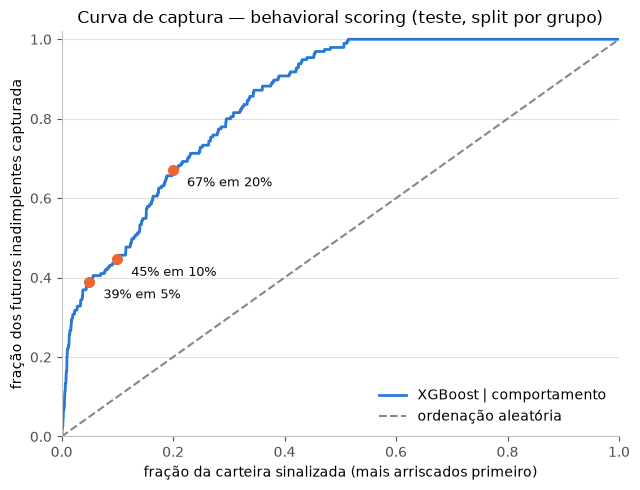

In [8]:
proba_ref = probas_beh[("XGBoost", "comportamento")]
ordem = np.argsort(-proba_ref)
y_ordenado = ys_te.values[ordem]
n_teste, n_positivos = len(y_ordenado), int(y_ordenado.sum())
taxa_base_teste = ys_te.mean()

linhas = []
for k in (0.5, 1, 2, 5, 10, 20, 30):
    n_flag = int(np.ceil(n_teste * k / 100))
    capturados = int(y_ordenado[:n_flag].sum())
    precisao = capturados / n_flag
    linhas.append({"top k% mais arriscados": f"{k}%", "snapshots sinalizados": n_flag, "inadimplentes capturados": capturados,
                   "captura (% de todos)": capturados / n_positivos, "precision na fatia": precisao, "lift": precisao / taxa_base_teste})
captura = pd.DataFrame(linhas).set_index("top k% mais arriscados")
captura_fmt = captura.assign(**{
    "captura (% de todos)": captura["captura (% de todos)"].map("{:.1%}".format),
    "precision na fatia": captura["precision na fatia"].map("{:.1%}".format),
    "lift": captura["lift"].map("{:.1f}x".format),
})
display(captura_fmt)

# curva de captura acumulada
fracao_sinalizada = np.arange(1, n_teste + 1) / n_teste
captura_acumulada = np.cumsum(y_ordenado) / n_positivos
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(fracao_sinalizada, captura_acumulada, color="#2a78d6", linewidth=2, label="XGBoost | comportamento")
ax.plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1.5, label="ordenação aleatória")
for k in (0.05, 0.10, 0.20):
    i = int(np.ceil(n_teste * k)) - 1
    ax.plot([k], [captura_acumulada[i]], marker="o", color="#eb6834", markersize=7)
    ax.annotate(f"{captura_acumulada[i]:.0%} em {k:.0%}", (k, captura_acumulada[i]), xytext=(10, -12), textcoords="offset points", fontsize=9, color="#0b0b0b")
ax.set_xlabel("fração da carteira sinalizada (mais arriscados primeiro)")
ax.set_ylabel("fração dos futuros inadimplentes capturada")
ax.set_title("Curva de captura — behavioral scoring (teste, split por grupo)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#c3c2b7"); ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors="#52514e"); ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

O 1% mais arriscado da carteira concentra mais de 20% de todos os futuros inadimplentes — um lift acima de 20 vezes em relação a escolher ao acaso. Os 10% mais arriscados concentram quase metade. Para uma ação de cobrança preventiva com capacidade limitada, isso é exatamente a informação que importa, e o modelo a entrega com folga. O mesmo modelo que tem F1 de 0,2 é um modelo útil.

Resta mostrar que o F1 baixo é mesmo efeito da prevalência, e não uma limitação escondida do ordenador. O experimento abaixo usa **as mesmas previsões** do teste, sem retreinar nada, e apenas subamostra os negativos para simular carteiras com prevalência maior. Se o F1 máximo subir com a prevalência, o ordenador era bom o tempo todo; o número baixo era a raridade.

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
idx_pos = np.where(ys_te.values == 1)[0]
idx_neg = np.where(ys_te.values == 0)[0]

linhas = []
for prevalencia in (taxa_base_teste, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50):
    n_neg = int(len(idx_pos) * (1 - prevalencia) / prevalencia)
    if n_neg > len(idx_neg):
        continue
    f1s, precisoes, recalls = [], [], []
    for _ in range(10):
        selecao = np.concatenate([idx_pos, rng.choice(idx_neg, n_neg, replace=False)])
        p, r, _ = precision_recall_curve(ys_te.values[selecao], proba_ref[selecao])
        f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
        i = np.nanargmax(f1)
        f1s.append(f1[i]); precisoes.append(p[i]); recalls.append(r[i])
    linhas.append({"prevalência simulada": prevalencia, "F1 máximo": np.mean(f1s), "precision": np.mean(precisoes), "recall": np.mean(recalls)})

f1_vs_prev = pd.DataFrame(linhas)
f1_vs_prev["prevalência simulada"] = f1_vs_prev["prevalência simulada"].map("{:.1%}".format)
f1_vs_prev.set_index("prevalência simulada").round(3)

,F1 máximo,precision,recall
prevalência simulada,,,
0.8%,0.187,0.163,0.221
2.0%,0.285,0.284,0.288
5.0%,0.376,0.484,0.308
10.0%,0.440,0.533,0.375
20.0%,0.551,0.449,0.724
30.0%,0.654,0.525,0.869
50.0%,0.801,0.679,0.981


Mesmo ordenador, mesmas probabilidades: o F1 máximo vai de 0,2 na prevalência real para 0,45 a 5%, 0,50 a 10% e acima de 0,8 a 50%. Nada no modelo mudou entre uma linha e outra — só a proporção de negativos. É a demonstração mais direta de que, para uma classe muito rara, **o F1 no limiar é uma régua que mede a prevalência tanto quanto mede o modelo**. Comparar F1 entre problemas com prevalências diferentes, ou julgar um modelo de evento raro por um F1 "baixo" em termos absolutos, é um erro comum; as réguas adequadas são ROC-AUC e average precision (para a qualidade da ordenação) e a captura nos top-k% (para a utilidade operacional), com o ponto de corte decidido pelo custo de cada erro e pela capacidade de ação da área.

## Técnica 2 — rodada final sobre os dados deduplicados

Fica uma última pergunta em aberto desde o Problema 1: e se, em vez de separar os gêmeos entre treino e teste, os colapsássemos em uma única linha por pessoa? É a versão mais limpa possível do *application scoring* nesta base: um cadastro por perfil, e o TARGET no nível da pessoa (mau pagador se alguma de suas contas atingiu 60+ dias). Sem gêmeos, um split estratificado simples volta a ser honesto, e a prevalência sobe — porque uma pessoa com várias contas tem mais chances de que alguma tenha atrasado, o que é, mais uma vez, o viés de exposição, agora no nível da pessoa.

In [10]:
agregado = base.groupby("grupo_perfil").agg(TARGET=("TARGET", "max"), n_contas=("ID", "size")).reset_index()
pessoas = base.drop_duplicates("grupo_perfil")[["grupo_perfil"] + colunas_cadastro].merge(agregado, on="grupo_perfil")
print(f"Pessoas (perfis distintos): {len(pessoas):,} | positivos: {int(pessoas['TARGET'].sum())} ({pessoas['TARGET'].mean():.2%})")
print("Contas por pessoa — média:", round(pessoas["n_contas"].mean(), 2), "| mediana:", int(pessoas["n_contas"].median()), "| máximo:", int(pessoas["n_contas"].max()))
print("\nTaxa de mau pagador por número de contas da pessoa (viés de exposição no nível pessoa):")
display(pessoas.groupby(pd.cut(pessoas["n_contas"], [0, 1, 2, 5, 10, 60]), observed=True)["TARGET"].agg(["mean", "size"]).round(3))

X_pes = codificar_cadastro(pessoas.drop(columns=["TARGET", "n_contas"])).drop(columns="grupo_perfil")
y_pes = pessoas["TARGET"].astype(int)
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(X_pes, y_pes, test_size=0.25, stratify=y_pes, random_state=RANDOM_STATE)
print(f"\nTreino: {len(Xp_tr):,} pessoas / {int(yp_tr.sum())} positivos | Teste: {len(Xp_te):,} pessoas / {int(yp_te.sum())} positivos")

cv_simples = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
spw_pes = (yp_tr == 0).sum() / yp_tr.sum()
resultados_pes = []
for nome_modelo, modelo in (
    ("Regressão logística", regressao_logistica()),
    ("Random Forest", RandomForestClassifier(class_weight="balanced_subsample", min_samples_leaf=20, n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1)),
    ("XGBoost", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, min_child_weight=10,
                              reg_lambda=10, scale_pos_weight=spw_pes / 2, eval_metric="aucpr", random_state=RANDOM_STATE, n_jobs=-1)),
):
    linha, _ = avaliar_honesto(nome_modelo, modelo, Xp_tr, yp_tr, Xp_te, yp_te, cv_simples)
    resultados_pes.append(linha)
pd.DataFrame(resultados_pes).set_index("modelo").round(3)

Pessoas (perfis distintos): 9,728 | positivos: 442 (4.54%)
Contas por pessoa — média: 3.75 | mediana: 3 | máximo: 51

Taxa de mau pagador por número de contas da pessoa (viés de exposição no nível pessoa):


,mean,size
n_contas,,
"(0, 1]",0.049,3137
"(1, 2]",0.029,1581
"(2, 5]",0.046,2805
"(5, 10]",0.049,1734
"(10, 60]",0.064,471



Treino: 7,296 pessoas / 332 positivos | Teste: 2,432 pessoas / 110 positivos


,"AP (out-of-fold, treino)",ROC-AUC (teste),AP (teste),F1 (teste),precision (teste),recall (teste),limiar
modelo,,,,,,,
Regressão logística,0.098,0.567,0.097,0.082,0.083,0.082,0.660
Random Forest,0.068,0.576,0.091,0.116,0.090,0.164,0.476
XGBoost,0.081,0.587,0.101,0.105,0.063,0.309,0.359


Com uma linha por pessoa e prevalência de 4,5% — quase três vezes a original — o cadastro continua onde estava: ROC-AUC entre 0,57 e 0,58, average precision em torno de 0,10, F1 abaixo de 0,13. A deduplicação faz o que promete (remove o vazamento sem precisar de split por grupo) e é a forma mais defensável de usar esta base para *application scoring*; o que ela não faz é criar informação onde não há. Note ainda a tabela de taxa por número de contas: pessoas com mais de dez contas têm taxa de mau pagador maior — o viés de exposição sobrevive à deduplicação, porque "mais contas" continua significando "mais chances de que alguma tenha atrasado".

## Fechamento

O que este notebook acrescenta aos dois anteriores cabe em quatro frases.

**Antes de modelar, procure gêmeos.** Linhas com atributos idênticos e IDs diferentes são comuns em bases reais (múltiplos produtos por cliente, reprocessamentos, bases sintéticas) e transformam um split aleatório em um teste de memória. `StratifiedGroupKFold` e afins custam uma linha de código e evitam relatórios sobre modelos que não existem.

**Meça o sinal antes de otimizar o modelo.** Uma tabela de AUC univariada leva um minuto e teria antecipado tudo o que a busca de hiperparâmetros do notebook anterior levou meia hora para não encontrar. Balanceamento, busca e calibração de limiar redistribuem erros; não fabricam informação.

**Controle a exposição pela construção do alvo, não por um atributo.** Um TARGET do tipo "algum dia atrasou" confunde risco com tempo de observação; janelas fixas de observação e performance resolvem isso na raiz, e os snapshots rolantes multiplicam os positivos sem inventar dados. O tamanho do histórico como atributo é a versão errada da mesma ideia.

**Para eventos raros, F1 no limiar é uma régua de prevalência.** O behavioral scoring desta base tem ROC-AUC honesta de 0,85 e concentra um quinto dos futuros inadimplentes no 1% mais arriscado da carteira — e F1 de 0,2. Os três números descrevem o mesmo modelo; os dois primeiros dizem o que ele vale, o terceiro diz quão raro é o evento. Reporte ROC-AUC, average precision e captura nos top-k%, e deixe o limiar para quem conhece o custo de cada erro.

O que uma versão de produção deste problema ainda precisaria, e que está fora do alcance desta base: informação sobre os solicitantes **recusados** (para não treinar só sobre aprovados — o viés de seleção discutido no primeiro notebook), atributos de comportamento além do status de pagamento (uso do limite, valor das faturas, contato com a central), e uma janela de performance definida em conjunto com a área de risco, em vez de escolhida por conveniência de dados.